In [9]:
# Phase 5 setup — install the Excel reader used by pandas\nimport sys\nimport subprocess\nimport importlib.util\n\nif importlib.util.find_spec('openpyxl') is None:\n    print('openpyxl is not installed. Installing it into the current Jupyter Python environment...')\n    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'openpyxl'])\nelse:\n    print('openpyxl is already installed.')\n\nimport openpyxl\nprint('openpyxl version:', openpyxl.__version__)\n

# Phase 5 — Python Exploratory Data Analysis (EDA)

## Analyse OTT Platform Viewing Patterns to Support Data-Driven Content Decisions

**Phase:** 5 — Python-Based Exploratory Data Analysis  
**Business scope:** 6 objectives, 30 business questions, hypothesis-linked EDA

### Run instructions
The first code cell automatically checks for and installs `openpyxl` if your Jupyter environment does not already have it.

Keep the five cleaned Excel files in the same folder as this notebook, then run the cells from top to bottom.

## Phase 5 Objectives

**O1 — Content Performance & Viewer Engagement**  
Identify high-performing content, genres and formats.

**O2 — Platform & Content Portfolio Performance**  
Compare platform catalogue and viewing performance.

**O3 — Viewing Behaviour Across Customer Segments**  
Understand viewing patterns across age, gender, region and engagement.

**O4 — Device & Time-Based Viewing Patterns**  
Understand how and when users watch.

**O5 — Subscription Retention & Churn**  
Explore renewal and churn patterns across plans, fees and engagement.

**O6 — Ratings, Feedback & Content Success**  
Explore viewer satisfaction, completion and rewatch patterns.

In [10]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Libraries loaded.")

Libraries loaded.


In [11]:
# PHASE 5 - Load Cleaned Excel Files
# This cell automatically installs openpyxl if required.

import sys
import subprocess
from pathlib import Path

# Check/install openpyxl
try:
    import openpyxl
    print("openpyxl is already installed.")
except ModuleNotFoundError:
    print("openpyxl is missing. Installing now...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "openpyxl"
    ])
    import openpyxl
    print("openpyxl installed successfully.")

print("openpyxl version:", openpyxl.__version__)

# Find the folder where this notebook is running
PROJECT_FOLDER = Path.cwd()

print("Current project folder:")
print(PROJECT_FOLDER)

# Check that all required files exist
required_files = [
    "user_profile_cleaned.xlsx",
    "content_library_cleaned.xlsx",
    "viewing_activity_cleaned.xlsx",
    "ratings_feedback_cleaned.xlsx",
    "subscription_retention_cleaned.xlsx"
]

print("\nChecking files...")

for file in required_files:
    path = PROJECT_FOLDER / file

    if path.exists():
        print("✓", file)
    else:
        print("✗ MISSING:", file)

# Load datasets
user = pd.read_excel(PROJECT_FOLDER / "user_profile_cleaned.xlsx")
content = pd.read_excel(PROJECT_FOLDER / "content_library_cleaned.xlsx")
viewing = pd.read_excel(PROJECT_FOLDER / "viewing_activity_cleaned.xlsx")
ratings = pd.read_excel(PROJECT_FOLDER / "ratings_feedback_cleaned.xlsx")
subscription = pd.read_excel(PROJECT_FOLDER / "subscription_retention_cleaned.xlsx")

print("\n======================================")
print("ALL 5 DATASETS LOADED SUCCESSFULLY")
print("======================================")

summary = pd.DataFrame({
    "Dataset": [
        "User Profile",
        "Content Library",
        "Viewing Activity",
        "Ratings & Feedback",
        "Subscription & Retention"
    ],
    "Rows": [
        len(user),
        len(content),
        len(viewing),
        len(ratings),
        len(subscription)
    ],
    "Columns": [
        user.shape[1],
        content.shape[1],
        viewing.shape[1],
        ratings.shape[1],
        subscription.shape[1]
    ]
})

display(summary)

openpyxl is already installed.
openpyxl version: 3.1.5
Current project folder:
C:\Users\ASUS\Desktop\final project\05_SPRINT_PHASE_05

Checking files...
✓ user_profile_cleaned.xlsx
✓ content_library_cleaned.xlsx
✓ viewing_activity_cleaned.xlsx
✓ ratings_feedback_cleaned.xlsx
✓ subscription_retention_cleaned.xlsx

ALL 5 DATASETS LOADED SUCCESSFULLY


,Dataset,Rows,Columns
0,User Profile,2000,9
1,Content Library,17797,19
2,Viewing Activity,30000,10
3,Ratings & Feedback,12000,5
4,Subscription & Retention,2000,5


In [12]:
def profile(name, df):
    return {
        "Dataset": name,
        "Rows": len(df),
        "Columns": df.shape[1],
        "Duplicate_Rows": int(df.duplicated().sum()),
        "Missing_Values": int(df.isna().sum().sum())
    }

quality = pd.DataFrame([
    profile("User Profile", user),
    profile("Content Library", content),
    profile("Viewing Activity", viewing),
    profile("Ratings & Feedback", ratings),
    profile("Subscription & Retention", subscription),
])

display(quality)

,Dataset,Rows,Columns,Duplicate_Rows,Missing_Values
0,User Profile,2000,9,0,0
1,Content Library,17797,19,0,3
2,Viewing Activity,30000,10,0,0
3,Ratings & Feedback,12000,5,0,0
4,Subscription & Retention,2000,5,0,0


## 1. Prepare Analytical Relationships

Use the Phase 2 validated relationships:

- `User_ID` connects User Profile with Viewing Activity and Subscription/Retention.
- `Content_ID` / `show_id` use the validated numeric key for Content Library joins.

In [13]:
# Content key
content = content.copy()
viewing = viewing.copy()
ratings = ratings.copy()

content["Content_Key"] = content["show_id"].astype(str).str.extract(r"(\d+)")[0].astype(int)
viewing["Content_Key"] = viewing["Content_ID"].astype(str).str.extract(r"(\d+)")[0].astype(int)
ratings["Content_Key"] = ratings["Content_ID"].astype(str).str.extract(r"(\d+)")[0].astype(int)

content_lookup = content.set_index("Content_Key")
user_lookup = user.set_index("User_ID")

viewing["Platform"] = viewing["Content_Key"].map(content_lookup["Platform"])
viewing["Title"] = viewing["Content_Key"].map(content_lookup["title"])
viewing["Content_Type"] = viewing["Content_Key"].map(content_lookup["type"])
viewing["listed_in"] = viewing["Content_Key"].map(content_lookup["listed_in"])
viewing["Primary_Genre"] = (
    viewing["listed_in"].fillna("Unknown").astype(str).str.split(",").str[0].str.strip()
)

for col in ["Age_Group","Gender","Region","Engagement_Level","Subscription_Type"]:
    viewing[col] = viewing["User_ID"].map(user_lookup[col])

ratings["Title"] = ratings["Content_Key"].map(content_lookup["title"])

match_rate = viewing["Content_Key"].isin(set(content["Content_Key"])).mean()
print(f"Viewing → Content match rate: {match_rate:.1%}")

Viewing → Content match rate: 100.0%


In [14]:
# Summary statistics required for Phase 5
eda_stats = pd.DataFrame({
    "Variable": [
        "Watch Duration",
        "Completion %",
        "Paused Times",
        "Rating",
        "Monthly Fee"
    ],
    "Mean": [
        viewing["Watch_Duration_Minutes"].mean(),
        viewing["Completion_Percentage"].mean(),
        viewing["Paused_Times"].mean(),
        ratings["Rating"].mean(),
        subscription["Monthly_Fee"].mean()
    ],
    "Median": [
        viewing["Watch_Duration_Minutes"].median(),
        viewing["Completion_Percentage"].median(),
        viewing["Paused_Times"].median(),
        ratings["Rating"].median(),
        subscription["Monthly_Fee"].median()
    ],
    "Std Dev": [
        viewing["Watch_Duration_Minutes"].std(),
        viewing["Completion_Percentage"].std(),
        viewing["Paused_Times"].std(),
        ratings["Rating"].std(),
        subscription["Monthly_Fee"].std()
    ],
    "Min": [
        viewing["Watch_Duration_Minutes"].min(),
        viewing["Completion_Percentage"].min(),
        viewing["Paused_Times"].min(),
        ratings["Rating"].min(),
        subscription["Monthly_Fee"].min()
    ],
    "Max": [
        viewing["Watch_Duration_Minutes"].max(),
        viewing["Completion_Percentage"].max(),
        viewing["Paused_Times"].max(),
        ratings["Rating"].max(),
        subscription["Monthly_Fee"].max()
    ]
})
display(eda_stats.round(2))

,Variable,Mean,Median,Std Dev,Min,Max
0,Watch Duration,181.00,61.0,412.24,5,12169
1,Completion %,52.36,53.0,28.08,0,100
2,Paused Times,1.49,1.0,1.12,0,3
3,Rating,3.01,3.0,1.41,1,5
4,Monthly Fee,296.04,299.0,245.19,0,599


# O1 — Content Performance & Viewer Engagement

Questions: Q1.1–Q1.5

,Title Count
listed_in,
Drama,1765
Dramas,1528
Comedy,1374
Action,1331
Comedies,1140
Documentary,952
Documentaries,817
International TV Shows,773
Action & Adventure,736


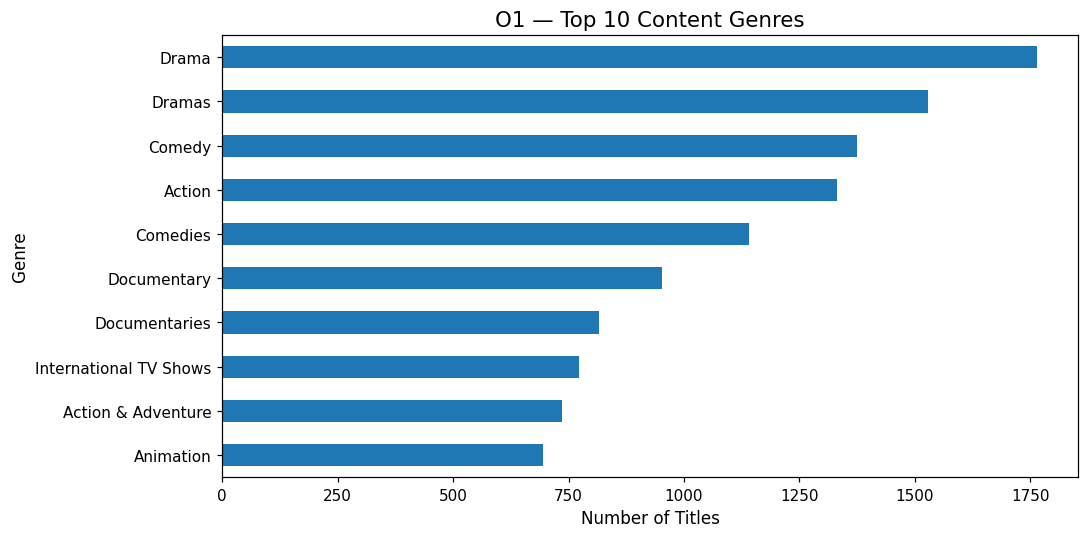

In [15]:
# Q1.1 — Top genres by title count
genre_counts = content["listed_in"].fillna("Unknown").astype(str).str.split(",").str[0].str.strip().value_counts().head(10)
display(genre_counts.to_frame("Title Count"))

plt.figure(figsize=(10,5))
genre_counts.sort_values().plot(kind="barh")
plt.title("O1 — Top 10 Content Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

,Average Completion %
Primary_Genre,
Period Drama,95.00
Mystery,94.00
Series,77.67
Concert Film,69.83
Faith and Spirituality,66.80
Variety,63.33
Fitness,63.14
Animation,60.05
Movies,59.05


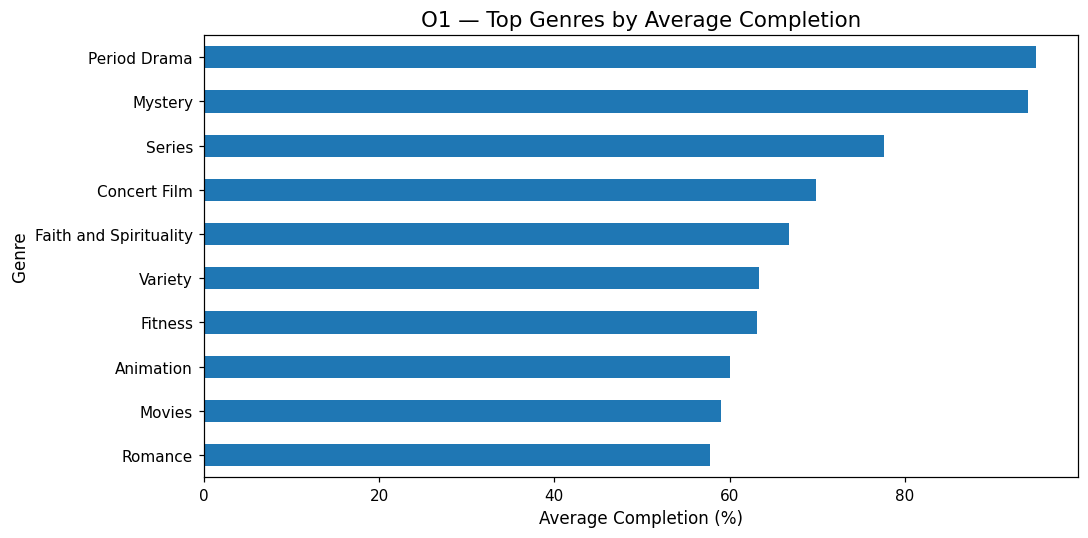

In [16]:
# Q1.2 — Completion by genre
genre_completion = viewing.groupby("Primary_Genre")["Completion_Percentage"].mean().sort_values(ascending=False).head(10)
display(genre_completion.to_frame("Average Completion %").round(2))

plt.figure(figsize=(10,5))
genre_completion.sort_values().plot(kind="barh")
plt.title("O1 — Top Genres by Average Completion")
plt.xlabel("Average Completion (%)")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

,Content_Type,Sessions,Avg_Watch_Duration,Avg_Completion
0,Movie,21862,49.19,53.22
1,TV Show,8138,535.08,50.04


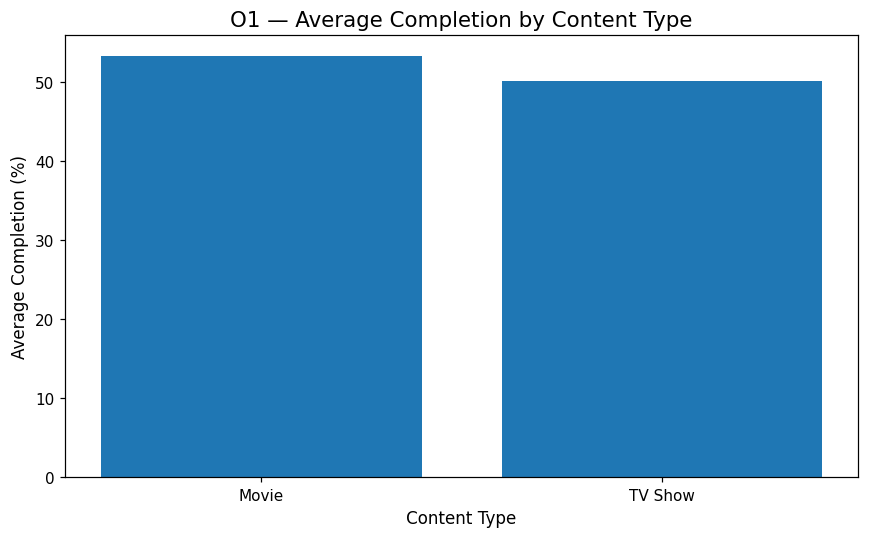

In [17]:
# Q1.3 — Movies vs TV Shows
format_summary = (
    viewing.groupby("Content_Type")
    .agg(
        Sessions=("Session_ID","count"),
        Avg_Watch_Duration=("Watch_Duration_Minutes","mean"),
        Avg_Completion=("Completion_Percentage","mean")
    )
    .reset_index()
)
display(format_summary.round(2))

plt.figure(figsize=(8,5))
plt.bar(format_summary["Content_Type"], format_summary["Avg_Completion"])
plt.title("O1 — Average Completion by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Average Completion (%)")
plt.tight_layout()
plt.show()

,Content_Age_Group,Avg_Popularity,Avg_Engagement,Titles
0,0–2 Years,11.32,7536.60,112
1,3–5 Years,8.54,2883.82,4309
2,6–10 Years,5.12,1851.78,8024
3,10+ Years,-0.81,-216.69,5352


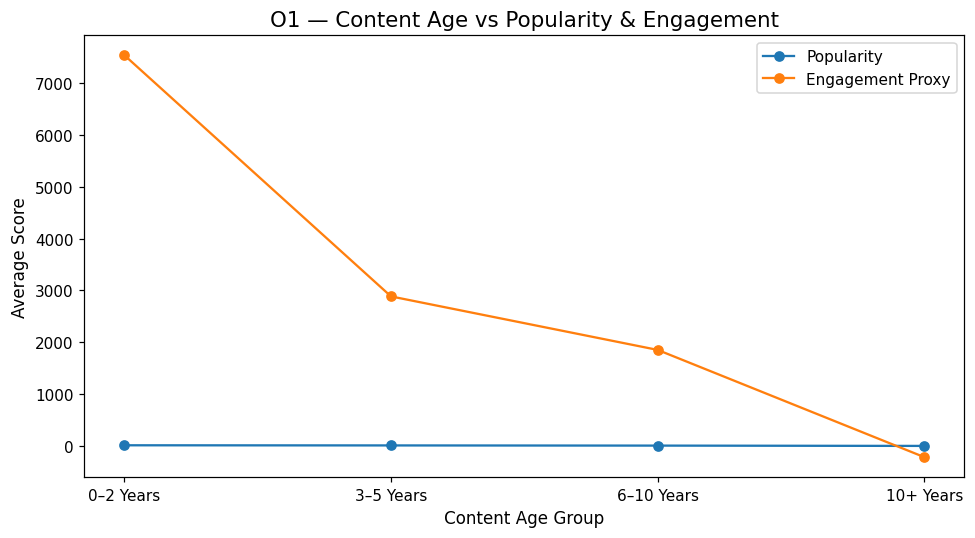

In [18]:
# Q1.4 — Content age and engagement
content["Content_Age_Group"] = pd.cut(
    content["Content_Age_Years"],
    bins=[-1,2,5,10,np.inf],
    labels=["0–2 Years","3–5 Years","6–10 Years","10+ Years"]
)

age_summary = (
    content.groupby("Content_Age_Group", observed=False)
    .agg(
        Avg_Popularity=("Popularity_Score","mean"),
        Avg_Engagement=("Engagement_Proxy","mean"),
        Titles=("show_id","count")
    )
    .reset_index()
)
display(age_summary.round(2))

plt.figure(figsize=(9,5))
plt.plot(age_summary["Content_Age_Group"].astype(str), age_summary["Avg_Popularity"], marker="o", label="Popularity")
plt.plot(age_summary["Content_Age_Group"].astype(str), age_summary["Avg_Engagement"], marker="o", label="Engagement Proxy")
plt.title("O1 — Content Age vs Popularity & Engagement")
plt.xlabel("Content Age Group")
plt.ylabel("Average Score")
plt.legend()
plt.tight_layout()
plt.show()

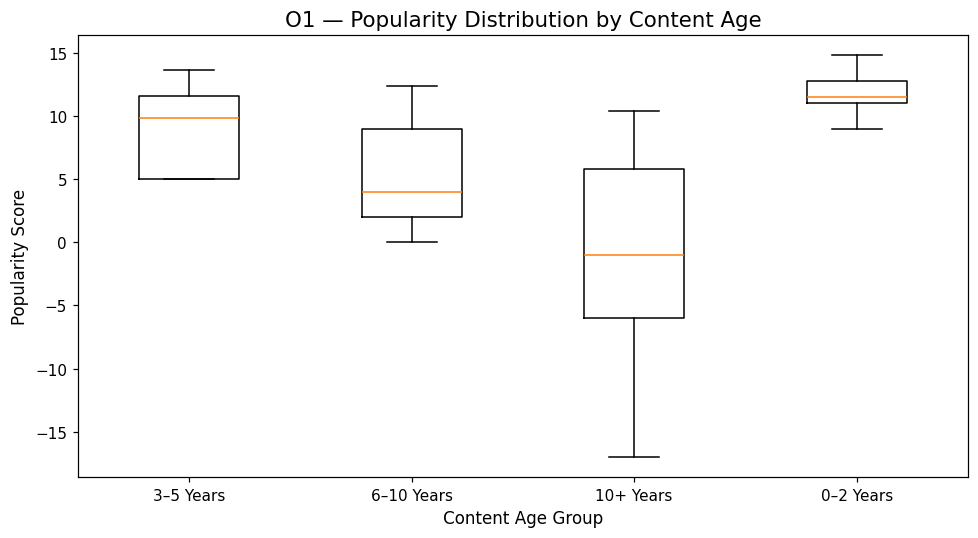

In [35]:
# Q1.4 distribution view — boxplot

groups = [
    content.loc[
        content["Content_Age_Group"] == g,
        "Popularity_Score"
    ].dropna()
    for g in content["Content_Age_Group"].dropna().unique()
]

labels = [
    str(g)
    for g in content["Content_Age_Group"].dropna().unique()
]

plt.figure(figsize=(9, 5))

plt.boxplot(
    groups,
    tick_labels=labels,
    showfliers=False
)

plt.title("O1 — Popularity Distribution by Content Age")
plt.xlabel("Content Age Group")
plt.ylabel("Popularity Score")

plt.tight_layout()
plt.show()

In [20]:
# Q1.5 — Top titles by popularity and engagement
top_titles = (
    content[["title","Popularity_Score","Engagement_Proxy"]]
    .sort_values(["Popularity_Score","Engagement_Proxy"], ascending=False)
    .head(10)
)
display(top_titles.round(2))

,title,Popularity_Score,Engagement_Proxy
5618,Louis C.K.: Hilarious,48.4,0.0
5370,Louis C.K. 2017,45.2,0.0
5637,Louis C.K.: Live at the Comedy Store,39.6,0.0
17712,Mirzapur Season 4,14.8,35520.0
17694,Mirzapur Season 3,14.4,25920.0
17680,Animal,14.0,2814.0
17604,Mirzapur,13.6,24480.0
17702,Made in Heaven Season 3,13.6,24480.0
17719,Mirzapur,13.6,24480.0
17749,Mirzapur,13.6,24480.0


### O1 EDA Observation
Record which genres/formats show stronger observed engagement, what pattern is visible across content age groups, and which titles have the strongest indicators.

**Do not claim statistical significance here.**

# O2 — Platform & Content Portfolio Performance
Questions: Q2.1–Q2.5

,Title Count
Platform,
NetStream,8431
AmazePrime,8168
DizPlay+,1198


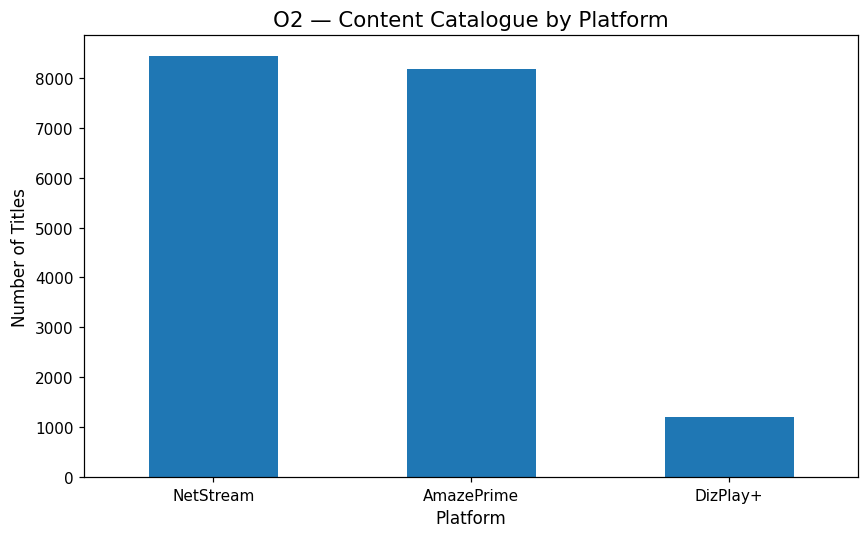

In [21]:
# Q2.1 — Catalogue size
platform_titles = content.groupby("Platform").size().sort_values(ascending=False)
display(platform_titles.to_frame("Title Count"))

plt.figure(figsize=(8,5))
platform_titles.plot(kind="bar")
plt.title("O2 — Content Catalogue by Platform")
plt.xlabel("Platform")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
# Q2.2–Q2.4 — Platform viewing summary
platform_summary = (
    viewing.groupby("Platform")
    .agg(
        Viewing_Sessions=("Session_ID","count"),
        Avg_Watch_Duration=("Watch_Duration_Minutes","mean"),
        Avg_Completion=("Completion_Percentage","mean")
    )
    .reset_index()
)
display(platform_summary.round(2))

,Platform,Viewing_Sessions,Avg_Watch_Duration,Avg_Completion
0,AmazePrime,13812,149.26,53.02
1,DizPlay+,2014,235.63,55.83
2,NetStream,14174,204.16,51.22


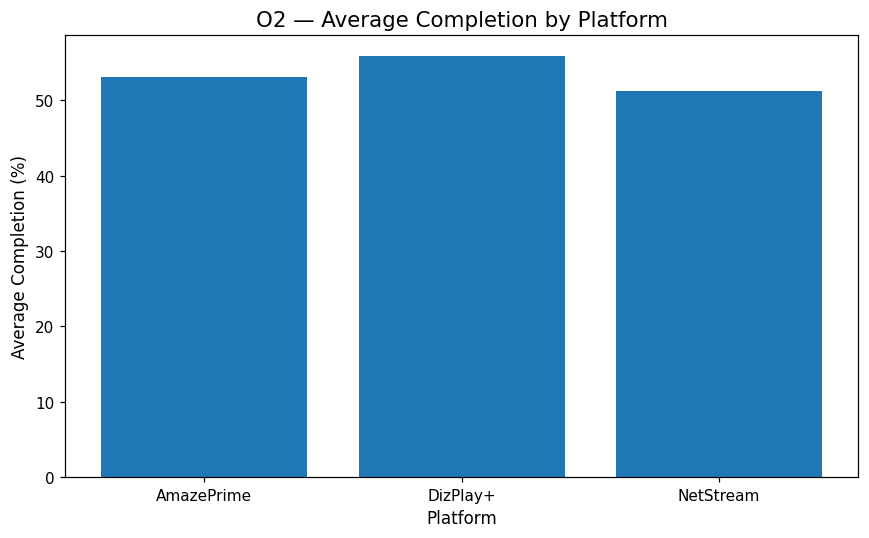

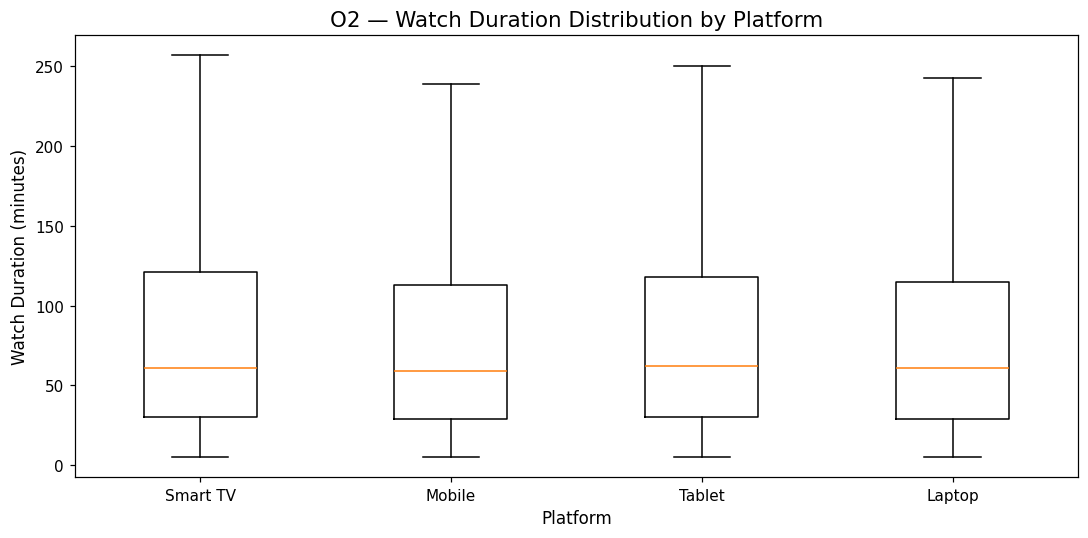

In [38]:
# Q2.3 — Completion by platform
plt.figure(figsize=(8,5))
plt.bar(platform_summary["Platform"], platform_summary["Avg_Completion"])
plt.title("O2 — Average Completion by Platform")
plt.xlabel("Platform")
plt.ylabel("Average Completion (%)")
plt.tight_layout()
plt.show()

# Q2.4 — Watch-duration distributions
platforms = viewing["Platform"].dropna().unique()
data = [viewing.loc[viewing["Platform"]==p,"Watch_Duration_Minutes"].dropna() for p in platforms]

plt.figure(figsize=(10,5))
plt.boxplot(
    device_data,
    tick_labels=device_types,
    showfliers=False
)
plt.title("O2 — Watch Duration Distribution by Platform")
plt.xlabel("Platform")
plt.ylabel("Watch Duration (minutes)")
plt.tight_layout()
plt.show()

In [24]:
# Q2.5 — Top genres within each platform by average completion
platform_genre = (
    viewing.groupby(["Platform","Primary_Genre"])["Completion_Percentage"]
    .mean().reset_index()
)
platform_genre["Rank"] = platform_genre.groupby("Platform")["Completion_Percentage"].rank(method="first", ascending=False)
top_platform_genres = platform_genre[platform_genre["Rank"]<=5].sort_values(["Platform","Completion_Percentage"], ascending=[True,False])
display(top_platform_genres.round(2))

,Platform,Primary_Genre,Completion_Percentage,Rank
22,AmazePrime,Period Drama,95.00,1.0
27,AmazePrime,Superhero,73.00,2.0
11,AmazePrime,Faith and Spirituality,66.80,3.0
13,AmazePrime,Fitness,63.14,4.0
23,AmazePrime,Romance,58.08,5.0
56,DizPlay+,Movies,93.00,1.0
59,DizPlay+,Mythology,90.00,2.0
63,DizPlay+,Series,77.67,3.0
45,DizPlay+,Concert Film,69.83,4.0
38,DizPlay+,Animation,68.75,5.0


# O3 — Viewing Behaviour Across Customer Segments
Questions: Q3.1–Q3.5

,Age_Group,Sessions,Avg_Watch_Duration,Avg_Completion
3,50+,7635,177.71,52.40
2,36-50,7620,188.32,52.60
1,26-35,7500,182.12,51.85
0,18-25,7245,175.60,52.57


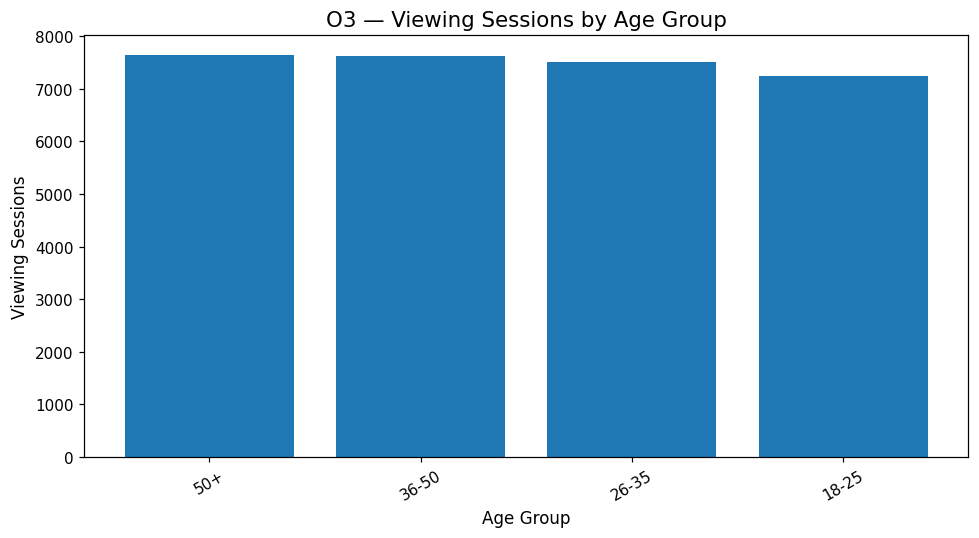

In [25]:
# Q3.1 and Q3.4 — Age group
age_viewing = (
    viewing.groupby("Age_Group")
    .agg(
        Sessions=("Session_ID","count"),
        Avg_Watch_Duration=("Watch_Duration_Minutes","mean"),
        Avg_Completion=("Completion_Percentage","mean")
    )
    .reset_index()
    .sort_values("Sessions", ascending=False)
)
display(age_viewing.round(2))

plt.figure(figsize=(9,5))
plt.bar(age_viewing["Age_Group"], age_viewing["Sessions"])
plt.title("O3 — Viewing Sessions by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Viewing Sessions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Engagement_Level,Low,Medium,High
Region,,,
Central,1875,2130,1875
East,1815,2400,2055
North,2370,1920,1890
South,1725,1890,1665
West,2250,2070,2070


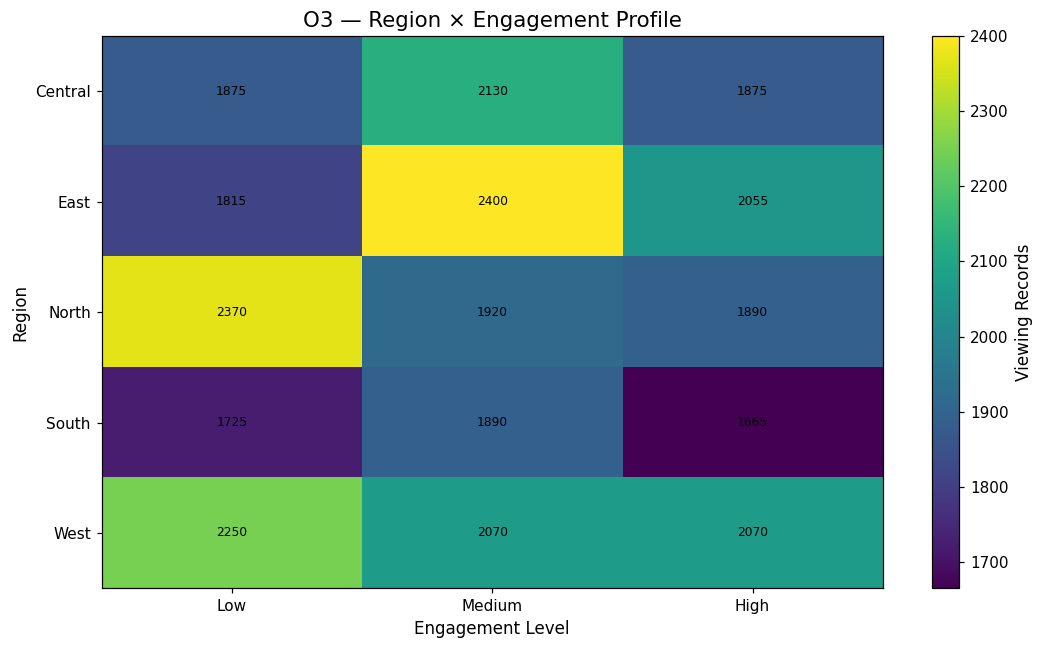

In [26]:
# Q3.2 — Region x engagement profile
region_engagement = pd.crosstab(viewing["Region"], viewing["Engagement_Level"])
for col in ["Low","Medium","High"]:
    if col not in region_engagement.columns:
        region_engagement[col] = 0
region_engagement = region_engagement[["Low","Medium","High"]]
display(region_engagement)

plt.figure(figsize=(10,6))
plt.imshow(region_engagement.values, aspect="auto")
plt.colorbar(label="Viewing Records")
plt.xticks(range(len(region_engagement.columns)), region_engagement.columns)
plt.yticks(range(len(region_engagement.index)), region_engagement.index)
plt.title("O3 — Region × Engagement Profile")
plt.xlabel("Engagement Level")
plt.ylabel("Region")
for i in range(region_engagement.shape[0]):
    for j in range(region_engagement.shape[1]):
        plt.text(j, i, region_engagement.iloc[i,j], ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

In [27]:
# Q3.3 — Gender comparison
gender_summary = (
    viewing.groupby("Gender")
    .agg(
        Sessions=("Session_ID","count"),
        Avg_Watch_Duration=("Watch_Duration_Minutes","mean"),
        Avg_Completion=("Completion_Percentage","mean")
    )
    .reset_index()
)
display(gender_summary.round(2))

,Gender,Sessions,Avg_Watch_Duration,Avg_Completion
0,Female,9870,182.50,52.55
1,Male,10290,180.15,52.55
2,Other,9840,180.37,51.96


,Average Completion %
Region,
North,52.88
East,52.83
South,52.42
Central,52.03
West,51.62


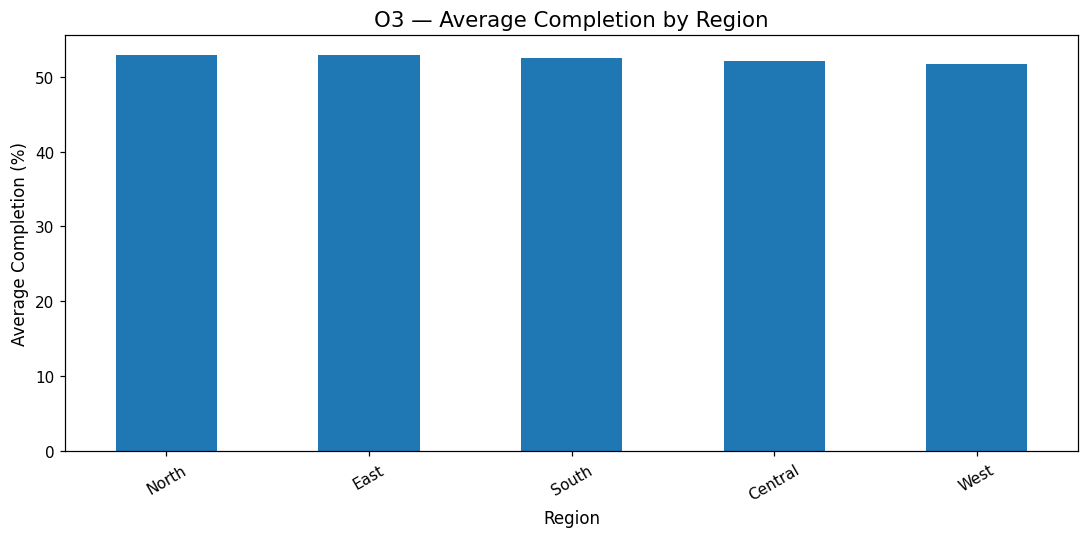

In [28]:
# Q3.5 — Completion by region
region_completion = viewing.groupby("Region")["Completion_Percentage"].mean().sort_values(ascending=False)
display(region_completion.to_frame("Average Completion %").round(2))

plt.figure(figsize=(10,5))
region_completion.plot(kind="bar")
plt.title("O3 — Average Completion by Region")
plt.xlabel("Region")
plt.ylabel("Average Completion (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# O4 — Device & Time-Based Viewing Patterns
Questions: Q4.1–Q4.5

In [29]:
# Q4.1–Q4.3 — Device summary
device_summary = (
    viewing.groupby("Device_Type")
    .agg(
        Sessions=("Session_ID","count"),
        Avg_Watch_Duration=("Watch_Duration_Minutes","mean"),
        Avg_Completion=("Completion_Percentage","mean")
    )
    .reset_index()
    .sort_values("Sessions", ascending=False)
)
display(device_summary.round(2))

,Device_Type,Sessions,Avg_Watch_Duration,Avg_Completion
2,Smart TV,7800,181.12,52.34
1,Mobile,7500,178.83,51.79
3,Tablet,7395,182.90,52.73
0,Laptop,7305,181.16,52.57


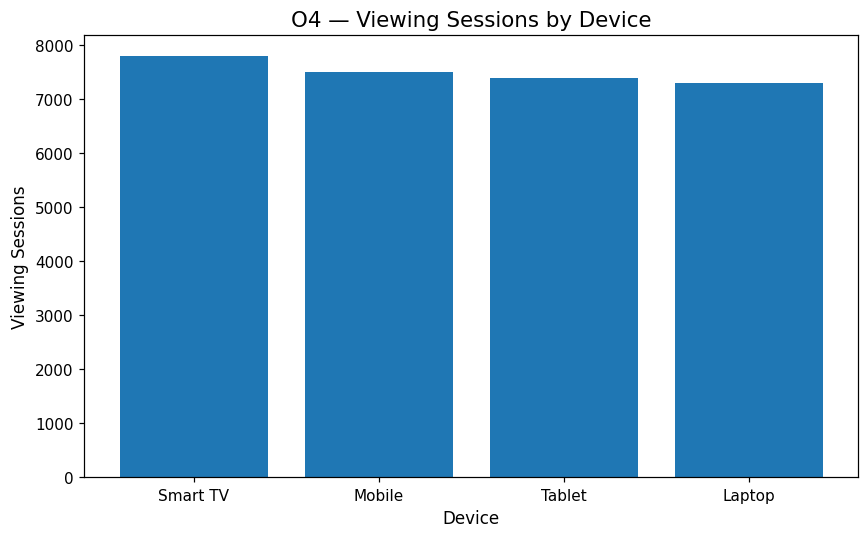

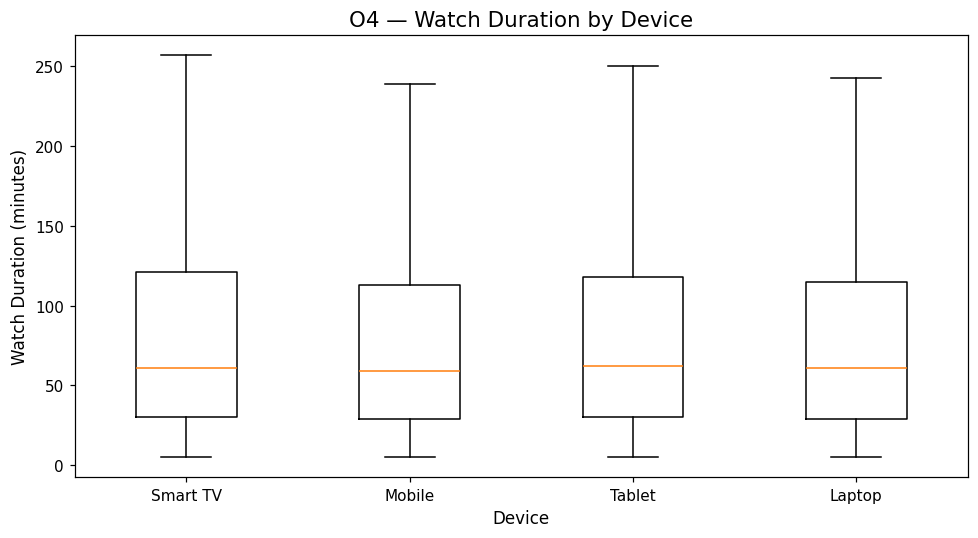

In [37]:
# Q4.1
plt.figure(figsize=(8,5))
plt.bar(device_summary["Device_Type"], device_summary["Sessions"])
plt.title("O4 — Viewing Sessions by Device")
plt.xlabel("Device")
plt.ylabel("Viewing Sessions")
plt.tight_layout()
plt.show()

# Q4.2 distribution
device_types = viewing["Device_Type"].dropna().unique()
device_data = [viewing.loc[viewing["Device_Type"]==d,"Watch_Duration_Minutes"].dropna() for d in device_types]

plt.figure(figsize=(9,5))
plt.boxplot(
    device_data,
    tick_labels=device_types,
    showfliers=False
)
plt.title("O4 — Watch Duration by Device")
plt.xlabel("Device")
plt.ylabel("Watch Duration (minutes)")
plt.tight_layout()
plt.show()

,Viewing Sessions
Time_of_Day,
Morning,7523
Afternoon,7445
Evening,7554
Night,7478


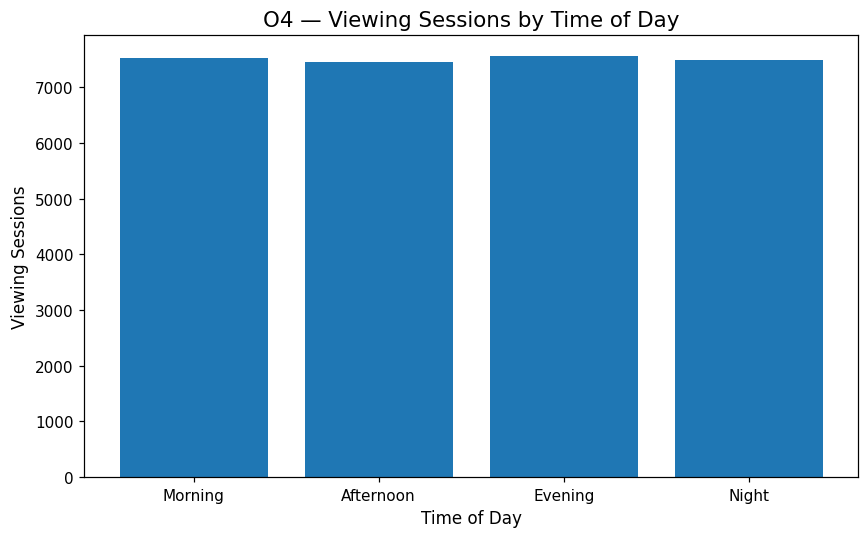

In [31]:
# Q4.4 — Time of day
time_counts = viewing["Time_of_Day"].value_counts()
order = ["Morning","Afternoon","Evening","Night"]
time_counts = time_counts.reindex([x for x in order if x in time_counts.index])

display(time_counts.to_frame("Viewing Sessions"))

plt.figure(figsize=(8,5))
plt.bar(time_counts.index, time_counts.values)
plt.title("O4 — Viewing Sessions by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Viewing Sessions")
plt.tight_layout()
plt.show()

Time_of_Day,Afternoon,Evening,Morning,Night
Device_Type,,,,
Laptop,189.93,193.01,165.40,175.43
Mobile,173.68,168.55,167.23,205.97
Smart TV,176.97,189.18,177.10,181.15
Tablet,183.22,190.33,158.92,199.65


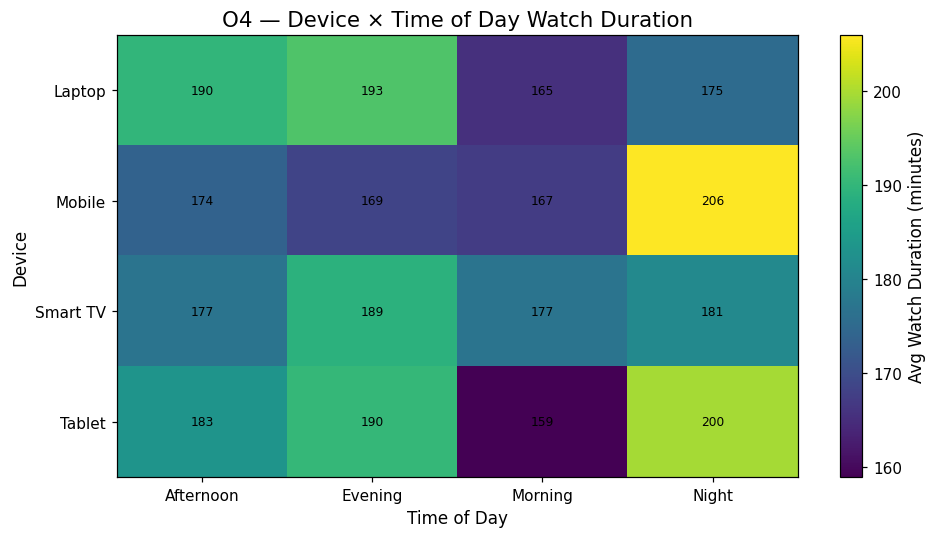

In [32]:
# Q4.5 — Device x time of day
device_time = viewing.groupby(["Device_Type","Time_of_Day"])["Watch_Duration_Minutes"].mean().unstack()

display(device_time.round(2))

plt.figure(figsize=(9,5))
plt.imshow(device_time.values, aspect="auto")
plt.colorbar(label="Avg Watch Duration (minutes)")
plt.xticks(range(len(device_time.columns)), device_time.columns)
plt.yticks(range(len(device_time.index)), device_time.index)
plt.title("O4 — Device × Time of Day Watch Duration")
plt.xlabel("Time of Day")
plt.ylabel("Device")
for i in range(device_time.shape[0]):
    for j in range(device_time.shape[1]):
        value = device_time.iloc[i,j]
        if pd.notna(value):
            plt.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

# O5 — Subscription Retention & Churn
Questions: Q5.1–Q5.5

In [33]:
retention = user[["User_ID","Engagement_Level","Age_Group","Region","Subscription_Type"]].merge(
    subscription, on="User_ID", how="left"
)
retention["Churn_Label"] = np.where(retention["Churn_Flag"]==1, "Churned", "Retained")
retention["Renewal_Label"] = np.where(retention["Renewal_Status"]=="Renewed", "Renewed", "Not Renewed")

display(retention.head())

,User_ID,Engagement_Level,Age_Group,Region,Subscription_Type_x,Subscription_Type_y,Monthly_Fee,Renewal_Status,Churn_Flag,Churn_Label,Renewal_Label
0,U0001,High,50+,West,Free Trial,Free Trial,0,Not Renewed,1,Churned,Not Renewed
1,U0002,Medium,50+,East,Basic,Basic,299,Renewed,0,Retained,Renewed
2,U0003,High,26-35,East,Free Trial,Free Trial,0,Renewed,0,Retained,Renewed
3,U0004,Medium,36-50,Central,Free Trial,Free Trial,0,Renewed,0,Retained,Renewed
4,U0005,Low,50+,Central,Premium,Premium,599,Not Renewed,1,Churned,Not Renewed


In [39]:
# O5 — Subscription Retention & Churn
# Q5.1–Q5.5

# Take customer characteristics from User Profile.
# Subscription information will come from the Subscription dataset
# to avoid duplicate Subscription_Type columns.

user_info = user[
    [
        "User_ID",
        "Engagement_Level",
        "Age_Group",
        "Region"
    ]
].copy()

subscription_info = subscription[
    [
        "User_ID",
        "Subscription_Type",
        "Monthly_Fee",
        "Churn_Flag",
        "Renewal_Status"
    ]
].copy()

# Merge customer information with subscription information
retention = user_info.merge(
    subscription_info,
    on="User_ID",
    how="left"
)

# Create analysis labels
retention["Churn_Label"] = np.where(
    retention["Churn_Flag"] == 1,
    "Churned",
    "Retained"
)

retention["Renewal_Label"] = np.where(
    retention["Renewal_Status"] == "Renewed",
    "Renewed",
    "Not Renewed"
)

print("O5 retention dataset created successfully.")
print("Rows:", len(retention))
print("Columns:", len(retention.columns))

display(retention.head())

O5 retention dataset created successfully.
Rows: 2000
Columns: 10


,User_ID,Engagement_Level,Age_Group,Region,Subscription_Type,Monthly_Fee,Churn_Flag,Renewal_Status,Churn_Label,Renewal_Label
0,U0001,High,50+,West,Free Trial,0,1,Not Renewed,Churned,Not Renewed
1,U0002,Medium,50+,East,Basic,299,0,Renewed,Retained,Renewed
2,U0003,High,26-35,East,Free Trial,0,0,Renewed,Retained,Renewed
3,U0004,Medium,36-50,Central,Free Trial,0,0,Renewed,Retained,Renewed
4,U0005,Low,50+,Central,Premium,599,1,Not Renewed,Churned,Not Renewed


In [40]:
# Q5.3 — Engagement vs churn
engagement_churn = retention.groupby("Engagement_Level").agg(
    Customers=("User_ID","count"),
    Churn_Rate=("Churn_Flag","mean")
).reset_index().sort_values("Churn_Rate", ascending=False)

display(engagement_churn.round(3))

,Engagement_Level,Customers,Churn_Rate
2,Medium,694,0.454
1,Low,669,0.445
0,High,637,0.432


In [41]:
# Q5.4 — Premium vs Basic
premium_basic = (
    retention[retention["Subscription_Type"].isin(["Basic","Premium"])]
    .groupby("Subscription_Type")
    .agg(
        Customers=("User_ID","count"),
        Renewal_Rate=("Renewal_Status", lambda x:(x=="Renewed").mean()),
        Churn_Rate=("Churn_Flag","mean"),
        Avg_Monthly_Fee=("Monthly_Fee","mean")
    )
    .reset_index()
)
display(premium_basic.round(3))

,Subscription_Type,Customers,Renewal_Rate,Churn_Rate,Avg_Monthly_Fee
0,Basic,660,0.576,0.424,299.0
1,Premium,659,0.810,0.190,599.0


,Monthly_Fee,Customers,Renewal_Rate,Churn_Rate
0,0,681,0.291,0.709
1,299,660,0.576,0.424
2,599,659,0.810,0.190


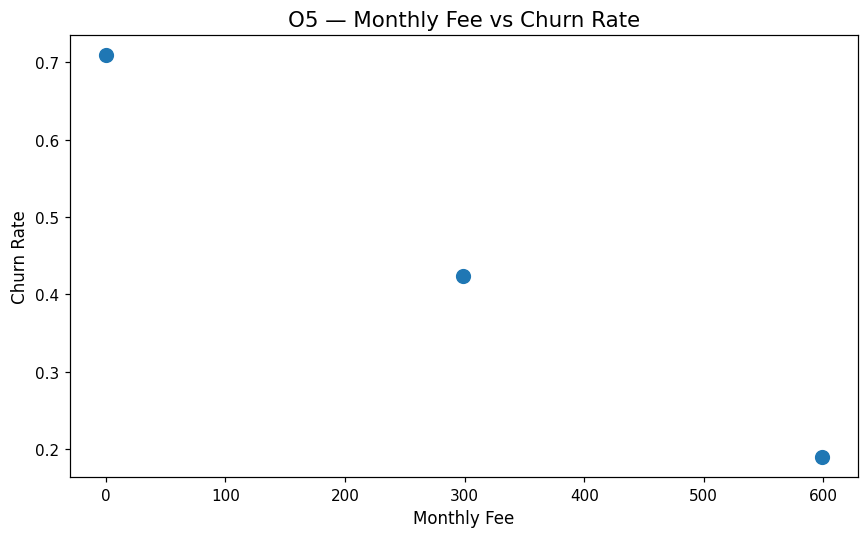

In [42]:
# Q5.5 — Monthly fee vs retention
fee_retention = (
    retention.groupby("Monthly_Fee")
    .agg(
        Customers=("User_ID","count"),
        Renewal_Rate=("Renewal_Status", lambda x:(x=="Renewed").mean()),
        Churn_Rate=("Churn_Flag","mean")
    )
    .reset_index()
    .sort_values("Monthly_Fee")
)
display(fee_retention.round(3))

plt.figure(figsize=(8,5))
plt.scatter(fee_retention["Monthly_Fee"], fee_retention["Churn_Rate"], s=80)
plt.xlabel("Monthly Fee")
plt.ylabel("Churn Rate")
plt.title("O5 — Monthly Fee vs Churn Rate")
plt.tight_layout()
plt.show()

# O6 — Ratings, Feedback & Content Success
Questions: Q6.1–Q6.5

In [43]:
# Rating / viewing relationship
view_pair = viewing.groupby(["User_ID","Content_ID"], as_index=False).agg(
    Avg_Completion=("Completion_Percentage","mean"),
    Rewatch_Rate=("Rewatched_Flag", lambda x:(x=="Y").mean())
)
ratings_view = ratings.merge(view_pair, on=["User_ID","Content_ID"], how="left")
ratings_view["Liked_Numeric"] = ratings_view["Liked_Flag"].eq("Y").astype(int)

In [44]:
# Q6.1 — Top-rated content
top_rated = ratings_view.groupby("Title")["Rating"].mean().sort_values(ascending=False).head(10)
display(top_rated.to_frame("Average Rating").round(2))

,Average Rating
Title,
å¿è€…iƒiƒƒiƒˆiƒªii‚“,5.0
i‡arsi Pazar,5.0
Zenon: Z3,5.0
Zara Si Bhool - A Small Mistake,5.0
100 Years: One Woman's Fight for Justice,5.0
"10,000 B.C.",5.0
Your Name Engraved Herein,5.0
Your Excellency,5.0
You're My Destiny,5.0


In [45]:
# Q6.2 — Top-liked content
top_liked = ratings_view.groupby("Title")["Liked_Numeric"].sum().sort_values(ascending=False).head(10)
display(top_liked.to_frame("Likes"))

,Likes
Title,
Unknown Title,10
Mirzapur,6
Those People,5
Breathe: Into the Shadows,5
Oddbods,5
Pacto de Fuga,5
Rangoon,5
Angel Beats!,4
"Best Wishes, Warmest Regards: A Schitt's Creek Farewell",4


,Feedback Count
Feedback_Category,
Positive,4836
Negative,4730
Neutral,2434


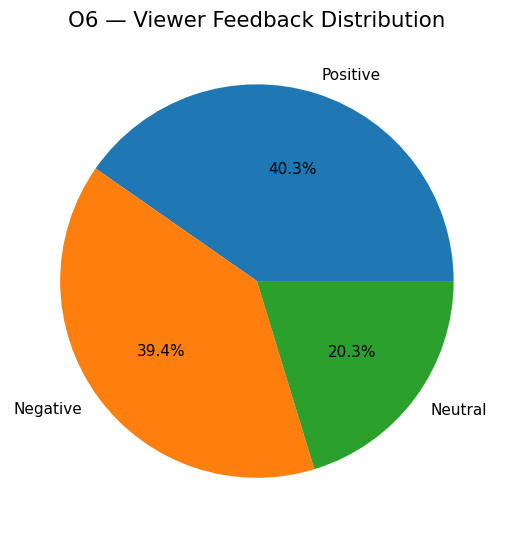

In [46]:
# Q6.3 — Feedback distribution
feedback_counts = ratings_view["Feedback_Category"].value_counts()
display(feedback_counts.to_frame("Feedback Count"))

plt.figure(figsize=(7,5))
plt.pie(feedback_counts.values, labels=feedback_counts.index, autopct="%1.1f%%")
plt.title("O6 — Viewer Feedback Distribution")
plt.tight_layout()
plt.show()

,Average Completion %
Rating,
1,93.00
2,73.25
4,35.00


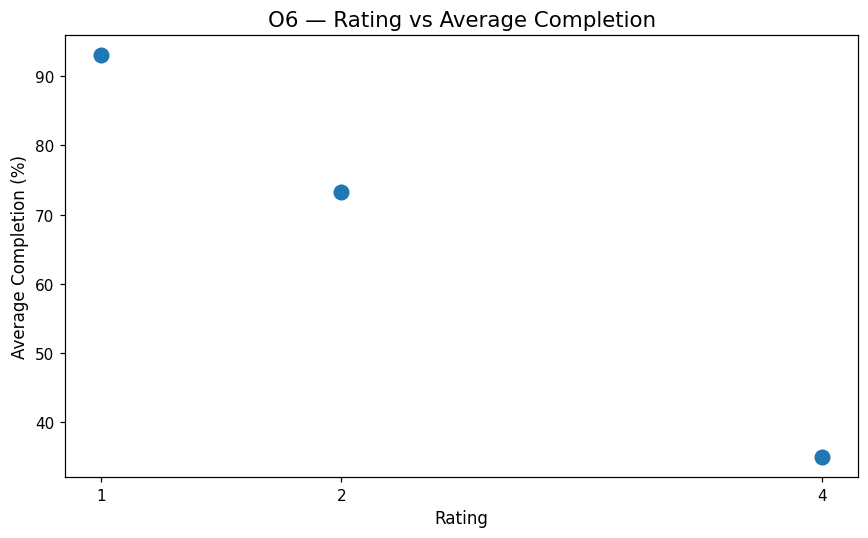

In [47]:
# Q6.4 — Rating vs completion
rating_completion = ratings_view.dropna(subset=["Avg_Completion"]).groupby("Rating")["Avg_Completion"].mean()
display(rating_completion.to_frame("Average Completion %").round(2))

plt.figure(figsize=(8,5))
plt.scatter(rating_completion.index, rating_completion.values, s=90)
plt.xlabel("Rating")
plt.ylabel("Average Completion (%)")
plt.title("O6 — Rating vs Average Completion")
plt.xticks(sorted(rating_completion.index))
plt.tight_layout()
plt.show()

,Rewatch Rate
Rating,
1,1.0
2,1.0
4,0.0


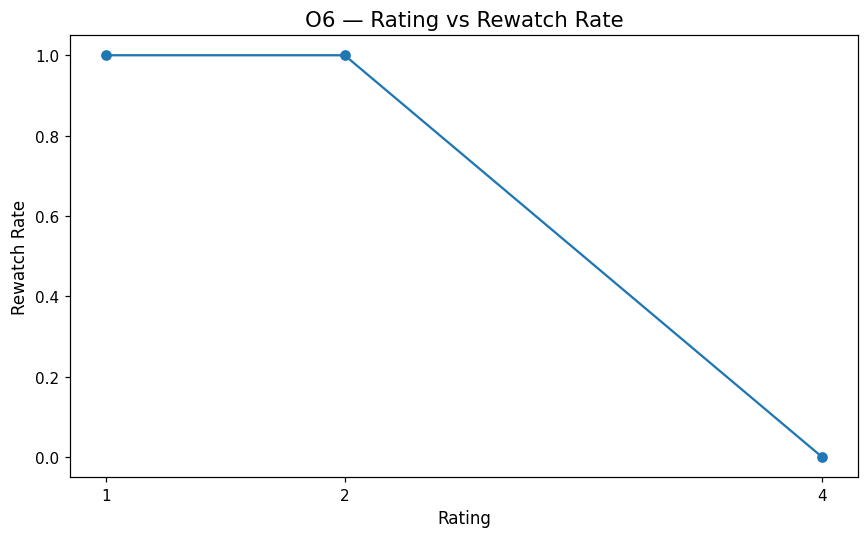

In [48]:
# Q6.5 — Rating vs rewatch
rating_rewatch = ratings_view.dropna(subset=["Rewatch_Rate"]).groupby("Rating")["Rewatch_Rate"].mean()
display(rating_rewatch.to_frame("Rewatch Rate").round(3))

plt.figure(figsize=(8,5))
plt.plot(rating_rewatch.index, rating_rewatch.values, marker="o")
plt.xlabel("Rating")
plt.ylabel("Rewatch Rate")
plt.title("O6 — Rating vs Rewatch Rate")
plt.xticks(sorted(rating_rewatch.index))
plt.tight_layout()
plt.show()

# 6. Correlation Analysis
This is exploratory and will not replace formal statistical testing.

In [49]:
corr_cols = ["Watch_Duration_Minutes","Completion_Percentage","Paused_Times"]
corr = viewing[corr_cols].corr()
display(corr.round(3))

,Watch_Duration_Minutes,Completion_Percentage,Paused_Times
Watch_Duration_Minutes,1.000,0.22,0.003
Completion_Percentage,0.220,1.00,0.000
Paused_Times,0.003,0.00,1.000


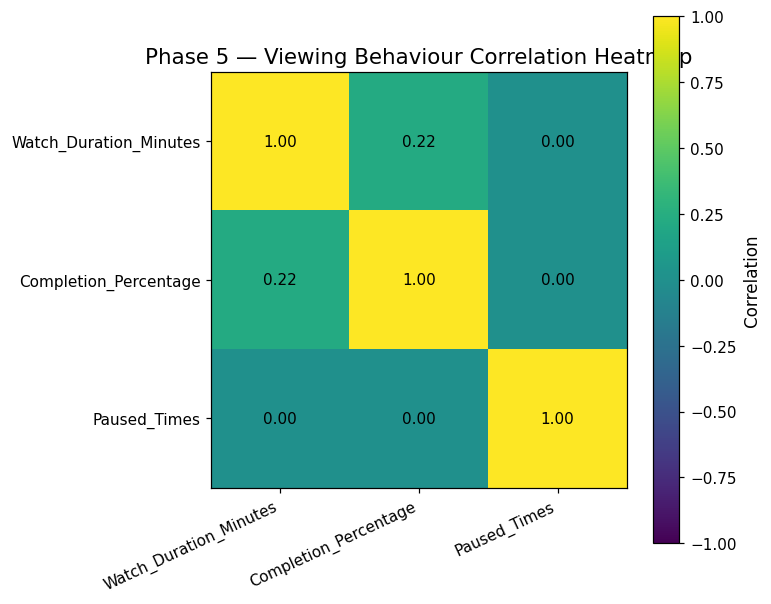

In [50]:
plt.figure(figsize=(7,6))
plt.imshow(corr.values, vmin=-1, vmax=1, aspect="equal")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=25, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Phase 5 — Viewing Behaviour Correlation Heatmap")
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()

# 7. Distribution Analysis — Watch Duration

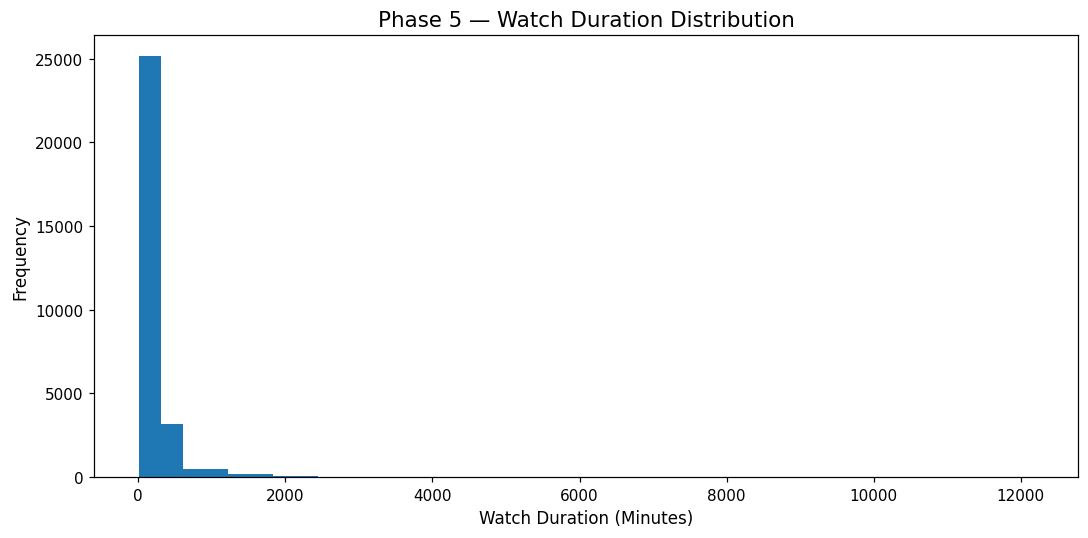

In [51]:
plt.figure(figsize=(10,5))
plt.hist(viewing["Watch_Duration_Minutes"], bins=40)
plt.title("Phase 5 — Watch Duration Distribution")
plt.xlabel("Watch Duration (Minutes)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

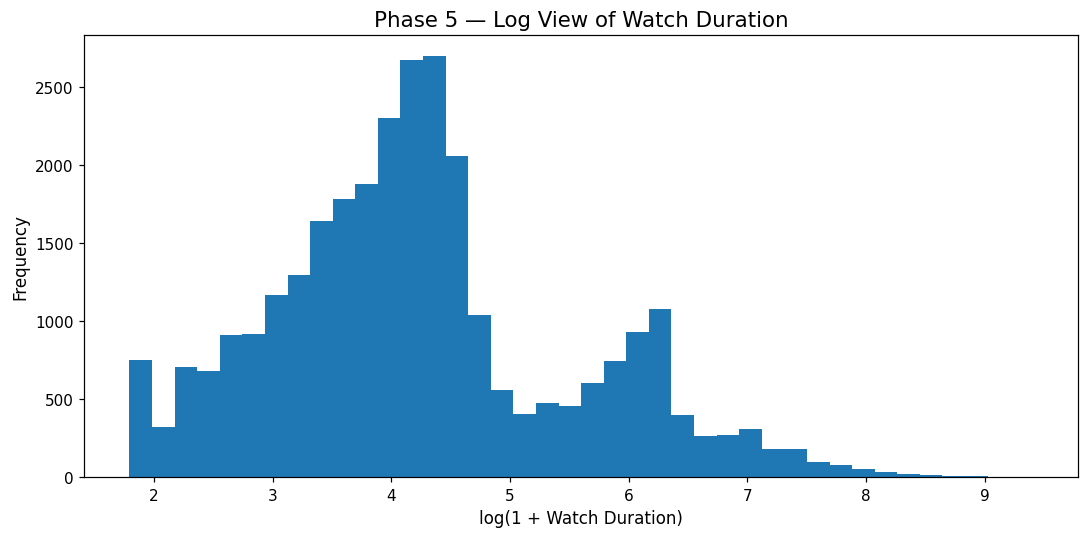

In [52]:
positive_watch = viewing.loc[viewing["Watch_Duration_Minutes"]>0,"Watch_Duration_Minutes"]
plt.figure(figsize=(10,5))
plt.hist(np.log1p(positive_watch), bins=40)
plt.title("Phase 5 — Log View of Watch Duration")
plt.xlabel("log(1 + Watch Duration)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 8. Boxplot — Completion by Content Type

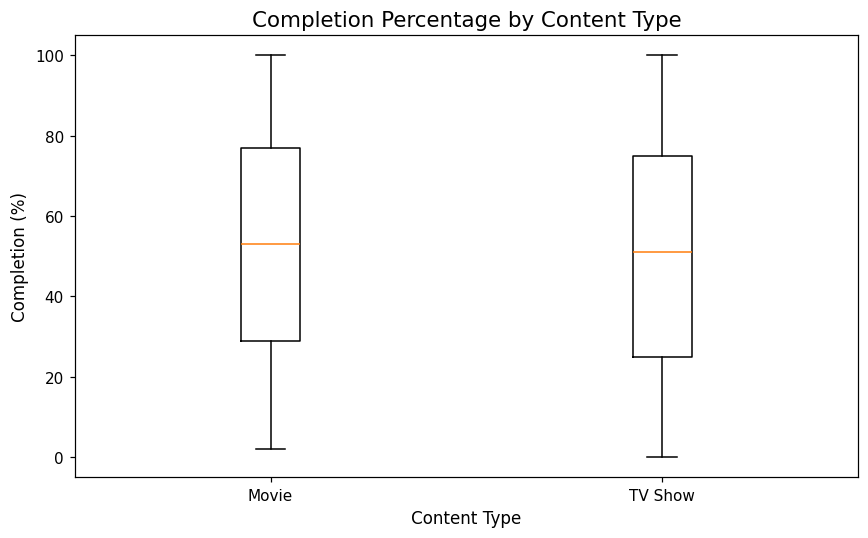

In [55]:
types = [x for x in viewing["Content_Type"].dropna().unique()]
data = [viewing.loc[viewing["Content_Type"]==x,"Completion_Percentage"].dropna() for x in types]

plt.figure(figsize=(8,5))
plt.boxplot(
    data,
    tick_labels=types,
    showfliers=False
)
plt.title("Completion Percentage by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Completion (%)")
plt.tight_layout()
plt.show()

# 9. Hypothesis-Linked EDA Observations

Use the following Phase 3 hypotheses as the bridge from EDA to later statistical validation:

- **H1 — Movies vs TV completion:** inspect group averages and boxplots.
- **H2 — Content age vs engagement:** inspect age-group trends.
- **H3 — Engagement vs churn:** inspect churn rate by engagement level.
- **H4 — Monthly fee vs retention:** inspect fee-level renewal/churn.
- **H5 — Rating vs completion:** inspect rating/completion trend and scatterplot.
- **H6 — Rating vs rewatch:** inspect rating/rewatch trend.

### Rule
EDA identifies patterns. It does **not** establish statistical significance or causation.

# 10. EDA Findings Template

## O1 — Content
**Finding:**  
**Business meaning:**  

## O2 — Platform
**Finding:**  
**Business meaning:**  

## O3 — Customer
**Finding:**  
**Business meaning:**  

## O4 — Device & Time
**Finding:**  
**Business meaning:**  

## O5 — Retention & Churn
**Finding:**  
**Business meaning:**  

## O6 — Ratings & Feedback
**Finding:**  
**Business meaning:**  

# 11. Phase 5 Conclusion

This notebook performs Python-based exploratory analysis on the same cleaned OTT datasets used in Phases 2–4. It covers summary statistics, distributions, group behaviour, correlations, histograms, boxplots, scatterplots and heatmap-style correlation analysis.

The EDA findings should be used to select and justify the relationships that move into formal statistical validation.